# GD-1 stream perturbation demo

This notebook loads the GD-1 progenitor phase-space state from the local data file, builds a stream from it with the Milky Way potential, and then compares the resulting stream to one generated with a localized Gaussian potential bump.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
from gala.units import UnitSystem
from astropy import units as u
import jax

jax.config.update("jax_enable_x64", True)

repo_root = Path.cwd()
if not (repo_root / "main.py").exists():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

usys = UnitSystem(u.kpc, u.Myr, u.Msun, u.radian)

from streamsculptor import potential
from main import Potential

/home/keir/miniconda3/envs/streamsculptor/lib/python3.11/site-packages/jax_cosmo/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [ ]:
class GaussianPotentialBump:
    def __init__(self, base_potential, amplitude_scale=0.1, width=0.5, seed=583):
        self.base_potential = base_potential
        self.amplitude_scale = amplitude_scale
        self.width = width
        self.seed = seed

    def potential(self, xyz, t):
        xyz = jnp.asarray(xyz)
        center = xyz
        base_value = self.base_potential.potential(center, t)
        base_strength = jnp.abs(base_value)

        amplitude = self.amplitude_scale * base_strength * jax.random.normal(
            jax.random.PRNGKey(self.seed), shape=()
        )

        delta = xyz - center
        radius2 = jnp.dot(delta, delta)
        return amplitude * jnp.exp(-0.5 * radius2 / (self.width**2))


# Load the GD-1 progenitor phase-space state today.
data_path = repo_root / "data" / "GD1_prog" / "GD1_progenitor.npy"
if not data_path.exists():
    data_path = repo_root.parent / "data" / "GD1_prog" / "GD1_progenitor.npy"

prog_wtoday = jnp.load(data_path, allow_pickle=True).item()
print(prog_wtoday)

pos = prog_wtoday.pos.xyz.to(u.kpc).value
vel = prog_wtoday.vel.d_xyz.to(u.kpc / u.Myr).value
w_today = jnp.hstack([pos, vel])
print("Observed GD-1 phase-space state today:", w_today)

base_potential = potential.GalaMilkyWayPotential(units=usys)
perturbation = GaussianPotentialBump(
    base_potential=base_potential,
    amplitude_scale=0.1,
    width=0.5,
    seed=583,
)

# Integrate the progenitor backward to its formation time.
t_age = 3_500  # Myr
ts_back = jnp.linspace(-t_age, 0.0, 1000)
init_cond = base_potential.integrate_orbit(w0=w_today, ts=ts_back, t0=-t_age, t1=0.0)
IC = init_cond.ys[-1]
print("GD-1 progenitor IC at t = -", t_age, "Myr:", IC)

# Build a stream release model around the progenitor state.
Mcluster0 = 1e4
Mcluster = jnp.linspace(Mcluster0, 0.0, len(ts_back))

stream_base = base_potential.gen_stream_scan(ts=ts_back, prog_w0=IC, Msat=Mcluster, seed_num=583)
stream_pert = base_potential.gen_stream_scan(
    ts=ts_back,
    prog_w0=IC,
    Msat=Mcluster,
    seed_num=583,
    potential_modifier=perturbation,
)

lead_base, trail_base = stream_base
lead_pert, trail_pert = stream_pert

print("Base stream leading arm shape:", lead_base.shape)
print("Perturbed stream leading arm shape:", lead_pert.shape)
print("Base stream trailing arm shape:", trail_base.shape)
print("Perturbed stream trailing arm shape:", trail_pert.shape)

NameError: name 'base_potential' is not defined

In [ ]:
# Compare the leading-arm release positions at a few stripping times.
example_indices = [0, 100, 500, 1000]
for idx in example_indices:
    if idx >= len(ts_back):
        continue
    x_release = IC[:3]
    v_release = IC[3:]
    lead_base_i, trail_base_i, _, _ = base_potential.release_model(
        x=x_release, v=v_release, Msat=Mcluster0, i=idx, t=ts_back[idx], seed_num=583, kval_arr=1.0, potential_modifier=None
    )
    lead_pert_i, trail_pert_i, _, _ = base_potential.release_model(
        x=x_release, v=v_release, Msat=Mcluster0, i=idx, t=ts_back[idx], seed_num=583, kval_arr=1.0, potential_modifier=perturbation
    )
    print(f"index={idx}")
    print("  base leading position:", np.array(lead_base_i))
    print("  perturbed leading position:", np.array(lead_pert_i))
    print("  position shift:", np.array(lead_pert_i - lead_base_i))

[[ 1.99949150e+01  0.00000000e+00  2.72911696e-04]
 [ 1.99955982e+01  0.00000000e+00  2.01846371e-04]
 [ 1.99957257e+01  0.00000000e+00 -1.13271236e-03]]
[[ 1.99996835e+01  0.00000000e+00  1.69886425e-05]
 [ 1.99997260e+01  0.00000000e+00  1.25648548e-05]
 [ 1.99997339e+01  0.00000000e+00 -7.05108858e-05]]


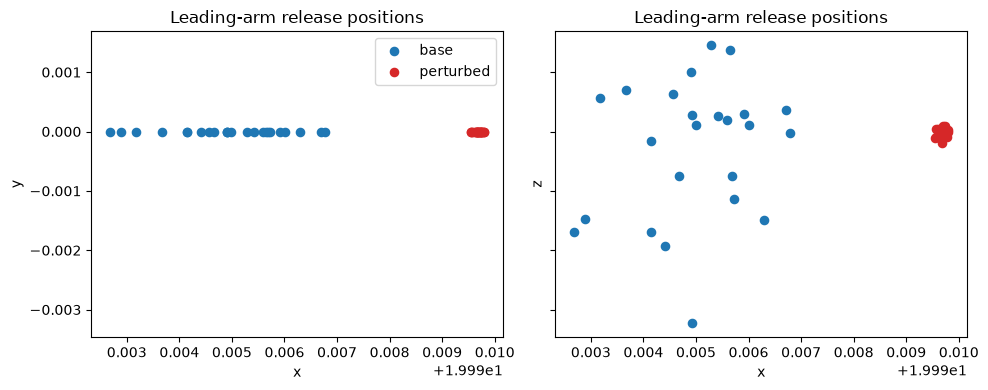

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

ax[0].scatter(lead_base[:, 1], lead_base[:, 2], s=8, color="tab:blue", alpha=0.5, label="base")
ax[0].scatter(lead_pert[:, 1], lead_pert[:, 2], s=8, color="tab:red", alpha=0.5, label="perturbed")
ax[0].set_title("Leading-arm initial conditions")
ax[0].set_xlabel("y [kpc]")
ax[0].set_ylabel("z [kpc]")
ax[0].legend()

ax[1].scatter(lead_base[:, 0], lead_base[:, 1], s=8, color="tab:blue", alpha=0.5, label="base")
ax[1].scatter(lead_pert[:, 0], lead_pert[:, 1], s=8, color="tab:red", alpha=0.5, label="perturbed")
ax[1].set_title("Leading-arm initial conditions")
ax[1].set_xlabel("x [kpc]")
ax[1].set_ylabel("y [kpc]")

plt.tight_layout()
plt.show()

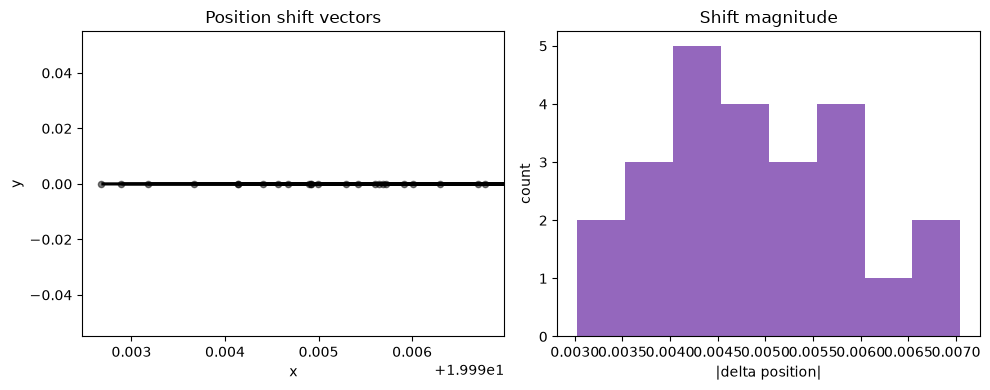

In [ ]:
# Compare the leading-arm displacement caused by the perturbation.
shift = lead_pert - lead_base
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].quiver(lead_base[:, 0], lead_base[:, 1], shift[:, 0], shift[:, 1], angles="xy", scale_units="xy", scale=1.0)
ax[0].scatter(lead_base[:, 0], lead_base[:, 1], s=12, color="k", alpha=0.4)
ax[0].set_title("Leading-arm position shift")
ax[0].set_xlabel("x [kpc]")
ax[0].set_ylabel("y [kpc]")

ax[1].hist(np.linalg.norm(shift, axis=1), bins=15, color="tab:purple")
ax[1].set_title("Shift magnitude")
ax[1].set_xlabel("|delta position|")
ax[1].set_ylabel("count")

plt.tight_layout()
plt.show()

The perturbation changes the release positions and velocities even though the same progenitor state and random seed are used. This is the intended behavior: the perturbation modifies the local tidal environment and therefore the initial stream phase-space coordinates.